In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from reporteeconomicolib.funciones import excluir_nombres, pagado_vs_porpagar, ingresos_vs_egresos, colorear_valor, convertir_float, deglos_ingresos_egresos

%matplotlib inline

## Porcentaje de expensas pagadas por mes

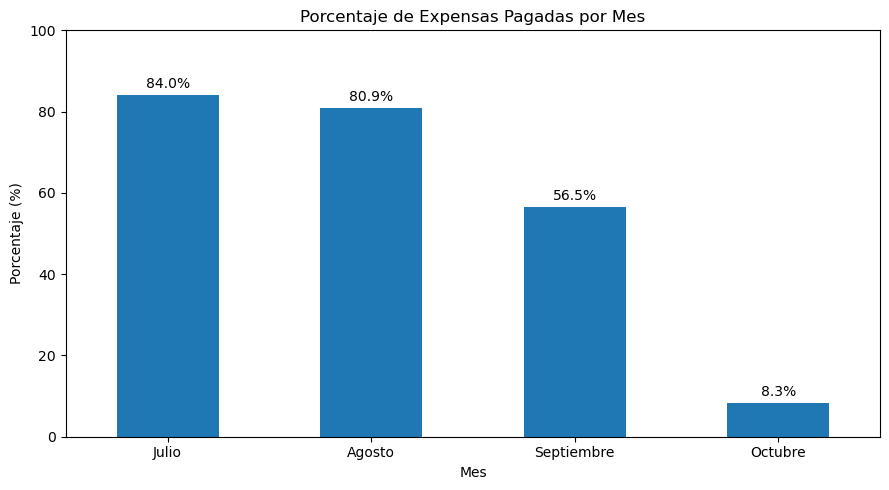

,TOTAL A PAGAR,PAGADO,% PAGADO
Julio,18680.97,15699.29,84.04
Agosto,18795.13,15202.29,80.88
Septiembre,18713.83,10582.60,56.55
Octubre,18968.99,1578.46,8.32


In [2]:
# Importa las planillas
df_julio_domestico = pd.read_csv(
    "planillas/julio_domestico.csv",
    sep=";",
    decimal=",",
    encoding="latin-1"
)
df_agosto_domestico = pd.read_csv(
    "planillas/agosto_domestico.csv",
    sep=";",
    decimal=",",
    encoding="latin-1"
)
df_septiembre_domestico = pd.read_csv(
    "planillas/septiembre_domestico.csv",
    sep=";",
    decimal=",",
    encoding="latin-1"
)
df_octubre_domestico = pd.read_csv(
    "planillas/octubre_domestico.csv",
    sep=";",
    decimal=",",
    encoding="latin-1"
)
# Importa los extractos
df_julio_extracto = pd.read_csv(
    "planillas/extractos/julio_2026_aprocesar.csv",
    sep=";",
    decimal=",",
    encoding="latin-1"
)

df_agosto_extracto = pd.read_csv(
    "planillas/extractos/agosto_2026_aprocesar.csv",
    sep=";",
    decimal=",",
    encoding="latin-1"
)

df_septiembre_extracto = pd.read_csv(
    "planillas/extractos/septiembre_2026_aprocesar.csv",
    sep=";",
    decimal=",",
    encoding="latin-1"
)
df_octubre_extracto = pd.read_csv(
    "planillas/extractos/octubre_2026_aprocesar.csv",
    sep=";",
    decimal=",",
    encoding="latin-1"
)
df_julio_domestico['PAGO?'] = df_julio_domestico['PAGO?'].fillna('')
df_agosto_domestico['PAGO?'] = df_agosto_domestico['PAGO?'].fillna('')
df_septiembre_domestico['PAGO?'] = df_septiembre_domestico['PAGO?'].fillna('')
df_octubre_domestico['PAGO?'] = df_octubre_domestico['PAGO?'].fillna('')

df_julio_domestico = excluir_nombres(df_julio_domestico)
df_agosto_domestico = excluir_nombres(df_agosto_domestico)
df_septiembre_domestico = excluir_nombres(df_septiembre_domestico)
df_octubre_domestico = excluir_nombres(df_octubre_domestico)

total_a_pagar_julio, total_pagado_julio = pagado_vs_porpagar(df_julio_domestico)
total_a_pagar_agosto, total_pagado_agosto = pagado_vs_porpagar(df_agosto_domestico)
total_a_pagar_septiembre, total_pagado_septiembre = pagado_vs_porpagar(df_septiembre_domestico)
total_a_pagar_octubre, total_pagado_octubre = pagado_vs_porpagar(df_octubre_domestico)

df_apagar_vs_pagado = pd.DataFrame({
    "TOTAL A PAGAR": [total_a_pagar_julio, total_a_pagar_agosto, total_a_pagar_septiembre, total_a_pagar_octubre],
    "PAGADO": [total_pagado_julio, total_pagado_agosto, total_pagado_septiembre, total_pagado_octubre]
})
# Asignar los meses
df_apagar_vs_pagado.index = [
    "Julio", "Agosto", "Septiembre", "Octubre"
]

# Calcular el porcentaje pagado
df_apagar_vs_pagado["% PAGADO"] = (round(
    df_apagar_vs_pagado["PAGADO"]
    .div(df_apagar_vs_pagado["TOTAL A PAGAR"].replace(0, float("nan")))
    .mul(100), 2)
)

# Crear el gráfico
ax = df_apagar_vs_pagado["% PAGADO"].plot(
    kind="bar",
    figsize=(9, 5),
    ylabel="Porcentaje (%)",
    xlabel="Mes",
    title="Porcentaje de Expensas Pagadas por Mes",
    ylim=(0, 100),
    rot=0
)

# Mostrar el porcentaje encima de cada barra
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()
df_apagar_vs_pagado

# Ingresos vs Egresos por mes

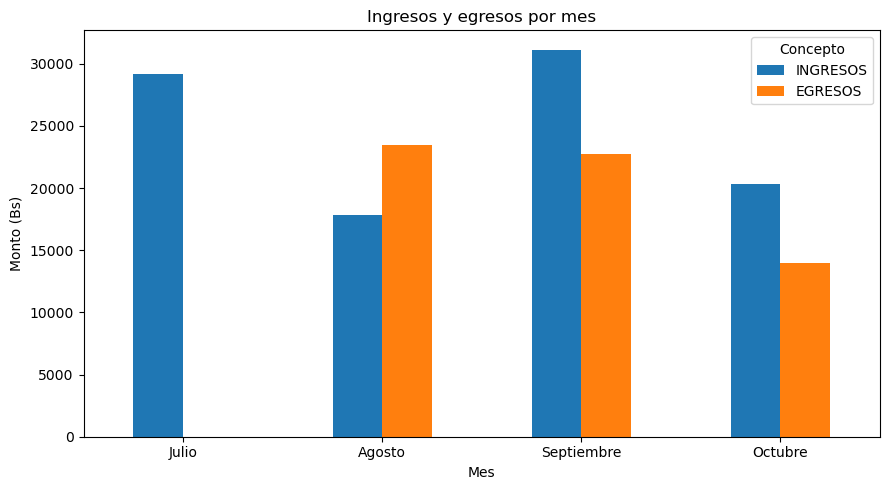

,INGRESOS,EGRESOS
Julio,29135.58,0.0
Agosto,17838.15,23480.7
Septiembre,31130.95,22706.9
Octubre,20341.74,13966.0


In [3]:
# Limpieza de datos
df_julio_extracto['Ingreso'] = df_julio_extracto['Ingreso'].fillna('')
df_julio_extracto['Egreso'] = df_julio_extracto['Egreso'].fillna('')
df_julio_extracto['Tipo'] = df_julio_extracto['Tipo'].fillna('')
df_agosto_extracto['Ingreso'] = df_agosto_extracto['Ingreso'].fillna('')
df_agosto_extracto['Egreso'] = df_agosto_extracto['Egreso'].fillna('')
df_agosto_extracto['Tipo'] = df_agosto_extracto['Tipo'].fillna('')
df_septiembre_extracto['Ingreso'] = df_septiembre_extracto['Ingreso'].fillna('')
df_septiembre_extracto['Egreso'] = df_septiembre_extracto['Egreso'].fillna('')
df_septiembre_extracto['Tipo'] = df_septiembre_extracto['Tipo'].fillna('')
df_octubre_extracto['Ingreso'] = df_octubre_extracto['Ingreso'].fillna('')
df_octubre_extracto['Egreso'] = df_octubre_extracto['Egreso'].fillna('')
df_octubre_extracto['Tipo'] = df_octubre_extracto['Tipo'].fillna('')
# Convertir a float
df_julio_extracto["Monto"] = df_julio_extracto["Monto"].apply(convertir_float)
df_julio_extracto["Saldo"] = df_julio_extracto["Saldo"].apply(convertir_float)

df_agosto_extracto["Monto"] = df_agosto_extracto["Monto"].apply(convertir_float)
df_agosto_extracto["Saldo"] = df_agosto_extracto["Saldo"].apply(convertir_float)

df_septiembre_extracto["Monto"] = df_septiembre_extracto["Monto"].apply(convertir_float)
df_septiembre_extracto["Saldo"] = df_septiembre_extracto["Saldo"].apply(convertir_float)

df_octubre_extracto["Monto"] = df_octubre_extracto["Monto"].apply(convertir_float)
df_octubre_extracto["Saldo"] = df_octubre_extracto["Saldo"].apply(convertir_float)
    
ingresos_julio, egresos_julio = ingresos_vs_egresos(df_julio_extracto)
ingresos_agosto, egresos_agosto = ingresos_vs_egresos(df_agosto_extracto)
ingresos_septiembre, egresos_septiembre = ingresos_vs_egresos(df_septiembre_extracto)
ingresos_octubre, egresos_octubre = ingresos_vs_egresos(df_octubre_extracto)

df_ingresos_vs_egresos = pd.DataFrame({
    "INGRESOS": [ingresos_julio, ingresos_agosto, ingresos_septiembre, ingresos_octubre],
    "EGRESOS": [egresos_julio, egresos_agosto, egresos_septiembre, egresos_octubre]
}, index = ["Julio", "Agosto", "Septiembre", "Octubre"])

# Generar el gráfico
df_ingresos_vs_egresos.plot(kind="bar", figsize=(9, 5))

plt.title("Ingresos y egresos por mes")
plt.xlabel("Mes")
plt.ylabel("Monto (Bs)")
plt.xticks(rotation=0)
plt.legend(title="Concepto")
plt.tight_layout()
plt.show()

df_ingresos_vs_egresos

# Análisis mes de Julio

La cuenta de la directiva del Sr. Edgar Paz inicio en fecha **17 de Julio 2026**, la cual recibio **22646,68 Bs**. de ahorro de la anterior directiva, durante este periodo de 15 días no hubo gastos

## Desglose de Ingresos

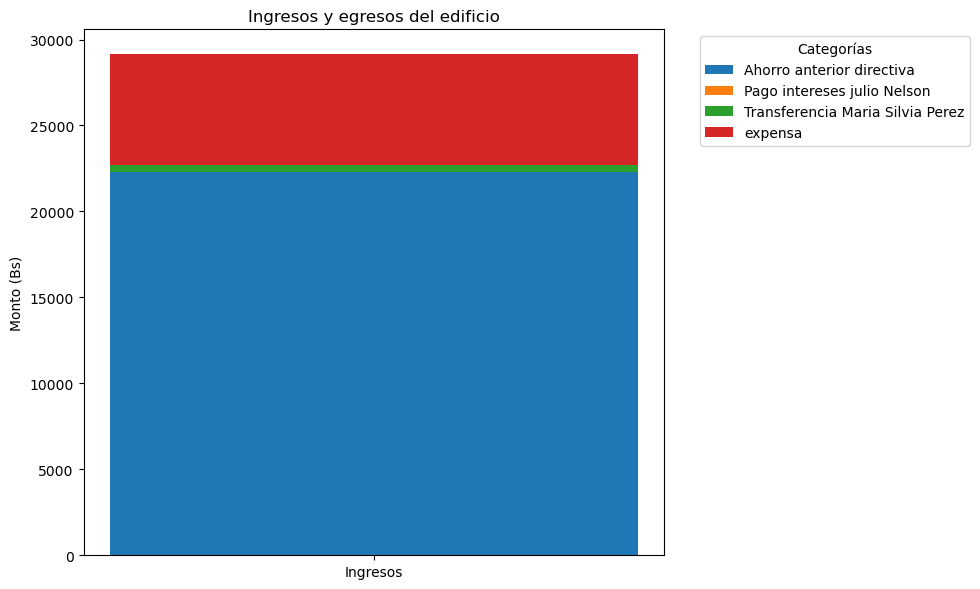

,Ingresos (Bs),Egresos (Bs),Saldo
Descripción,,,
Ahorro anterior directiva,"22,281.74",0.00,"22,281.74"
Pago intereses julio Nelson,15.55,0.00,15.55
Transferencia Maria Silvia Perez,400.00,0.00,400.00
expensa,"6,438.29",0.00,"6,438.29"
TOTAL,"29,135.58",0.00,"29,135.58"


In [4]:
deglos_ingresos_egresos(df_julio_extracto)

# Analisis mes de Agosto

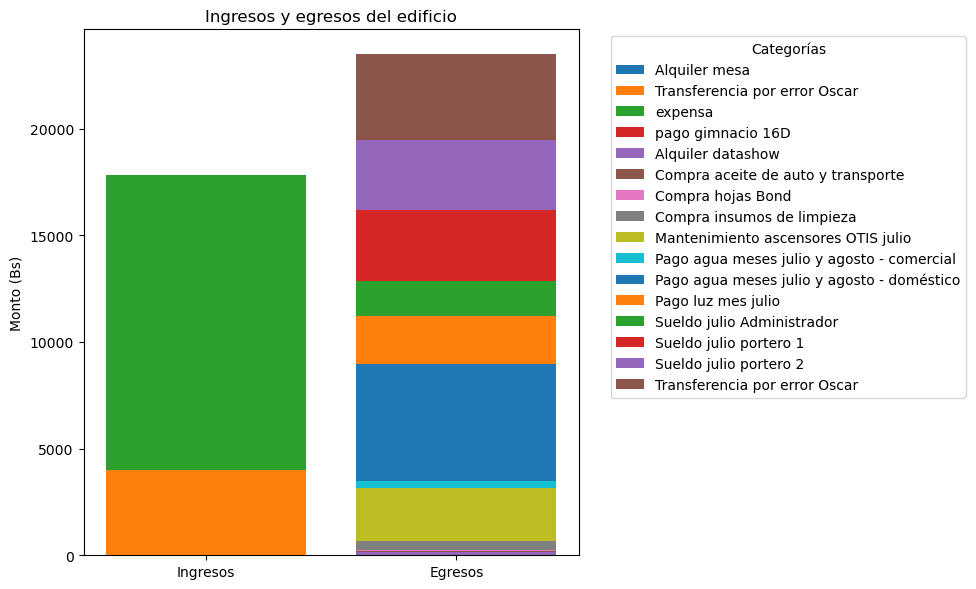

,Ingresos (Bs),Egresos (Bs),Saldo
Descripción,,,
Alquiler mesa,10.00,0.00,10.00
Transferencia por error Oscar,"4,000.00","4,000.00",0.00
expensa,"13,798.15",0.00,"13,798.15"
pago gimnacio 16D,30.00,0.00,30.00
Alquiler datashow,0.00,170.00,-170.00
Compra aceite de auto y transporte,0.00,28.00,-28.00
Compra hojas Bond,0.00,45.00,-45.00
Compra insumos de limpieza,0.00,415.00,-415.00
Mantenimiento ascensores OTIS julio,0.00,"2,500.00","-2,500.00"


In [5]:
deglos_ingresos_egresos(df_agosto_extracto)

# Analisis mes de Septiembre

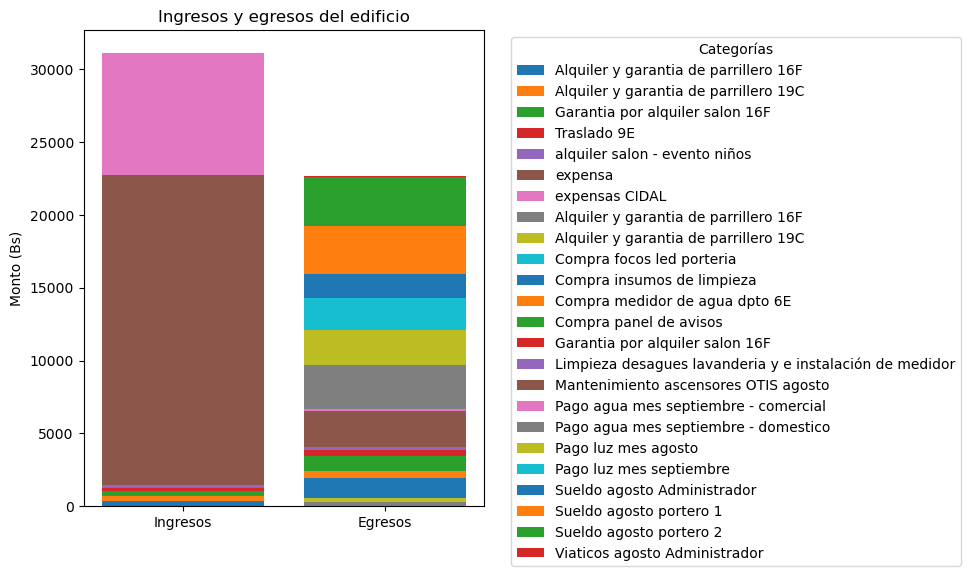

,Ingresos (Bs),Egresos (Bs),Saldo
Descripción,,,
Alquiler y garantia de parrillero 16F,370.00,300.00,70.00
Alquiler y garantia de parrillero 19C,300.00,250.00,50.00
Garantia por alquiler salon 16F,400.00,400.00,0.00
Traslado 9E,200.00,0.00,200.00
alquiler salon - evento niños,200.00,0.00,200.00
expensa,"21,256.11",0.00,"21,256.11"
expensas CIDAL,"8,404.84",0.00,"8,404.84"
Compra focos led porteria,0.00,40.00,-40.00
Compra insumos de limpieza,0.00,"1,350.00","-1,350.00"


In [6]:
deglos_ingresos_egresos(df_septiembre_extracto)

# Analisis mes de Octubre

El informe del mes mensionado tiene todas las transacciones registradas hasta el **día 23 del presente**

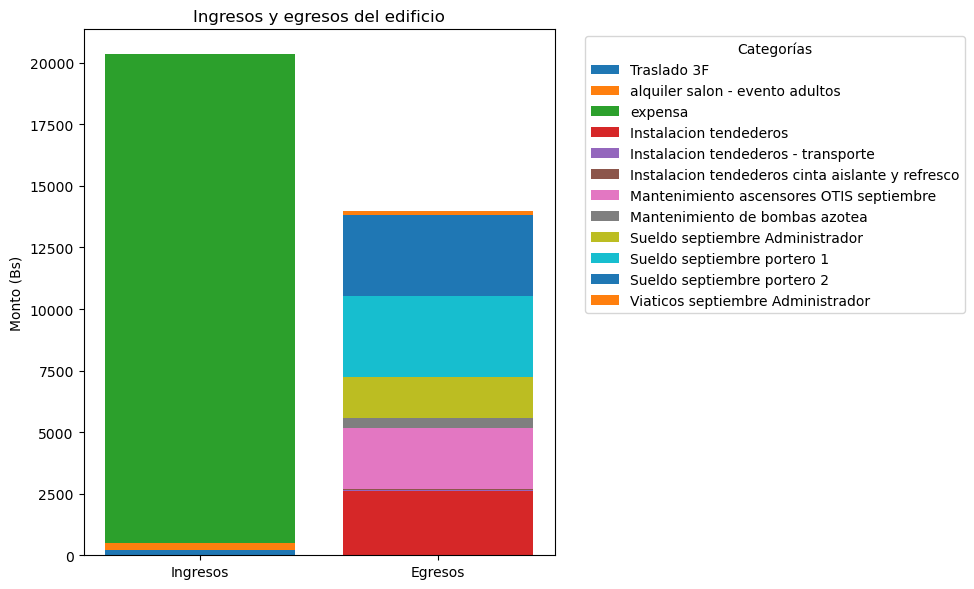

,Ingresos (Bs),Egresos (Bs),Saldo
Descripción,,,
Traslado 3F,200.00,0.00,200.00
alquiler salon - evento adultos,300.00,0.00,300.00
expensa,"19,841.74",0.00,"19,841.74"
Instalacion tendederos,0.00,"2,610.00","-2,610.00"
Instalacion tendederos - transporte,0.00,60.00,-60.00
Instalacion tendederos cinta aislante y refresco,0.00,16.00,-16.00
Mantenimiento ascensores OTIS septiembre,0.00,"2,500.00","-2,500.00"
Mantenimiento de bombas azotea,0.00,400.00,-400.00
Sueldo septiembre Administrador,0.00,"1,650.00","-1,650.00"


In [7]:
deglos_ingresos_egresos(df_octubre_extracto)

## Cuenta edificio por meses

El saldo final es hasta el 23 Octubre del presente

In [8]:
df_detalle_cuenta = pd.DataFrame({
    "Saldo Inicial": [0, 29135.58, 23493.03, 31917.08],
    "Saldo Final": [29135.58, 23493.03, 31917.08, 38292.82]
}, index = ["Julio", "Agosto", "Septiembre", "Octubre"])
df_detalle_cuenta

,Saldo Inicial,Saldo Final
Julio,0.00,29135.58
Agosto,29135.58,23493.03
Septiembre,23493.03,31917.08
Octubre,31917.08,38292.82
